# Randomized Training for Logistic Regression Model 
This notebook constructs the random-selection arm using the original 66%-agreement training split only. It deliberately leaves validation.csv for evaluation and does not read test.csv.
Here we instead split those 2,947 training examples into a smaller common starting set and a candidate pool. For a fair targeted-vs-random comparison, targeted training must start from the same common starting set and choose additions from the same candidate pool.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.base import clone

SEED= 42
TEXT_COL= "sentence_clean"
LABEL_COL= "label"
CLASS_ORDER= [0, 1, 2]
LABEL_NAMES= ["negative", "neutral", "positive"]
print("Working directory:", Path.cwd())
path= Path("Financial Phrasebank Project/data/splits")

train_df = pd.read_csv(path / "train.csv")
validation_df = pd.read_csv(path / "validation.csv")
print("Data directory:", path.resolve())
print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))

Working directory: /Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/Financial Phrasebank Project/notebooks
Data directory: /Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/Financial Phrasebank Project/notebooks/Financial Phrasebank Project/data/splits
Training rows: 2947
Validation rows: 632


## Stratification of existing training split
- base_df: never changes between runs; the model always begins with these sentences.
- candidate_pool: the only source of additional random examples.
The separate validation partition remains unchanged.


In [8]:
base_df, candidate_pool = train_test_split( train_df,test_size=0.30,stratify=train_df[LABEL_COL],
    random_state=SEED,)

assert train_df.index.is_unique
assert base_df.index.intersection(candidate_pool.index).empty
assert len(base_df) + len(candidate_pool)== len(train_df)

RESULTS_DIR= Path("results/randomized_logreg")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
base_df.to_csv(RESULTS_DIR / "common_base.csv", index=False)
candidate_pool.to_csv(RESULTS_DIR / "candidate_pool.csv", index=False)

print("Common baseline examples:", len(base_df))
print("Available additional examples:", len(candidate_pool))
print("Saved candidate pool to:", (RESULTS_DIR / "candidate_pool.csv").resolve())

Common baseline examples: 2062
Available additional examples: 885
Saved candidate pool to: /Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/Financial Phrasebank Project/notebooks/results/randomized_logreg/candidate_pool.csv


In [9]:
fixed_pipeline = Pipeline([
    ("features", TfidfVectorizer( analyzer="char",ngram_range=(3, 6),min_df=2,sublinear_tf=True,)),
    ("classifier", LogisticRegression(C=25,class_weight="balanced",solver="lbfgs",max_iter=1000,random_state=SEED,)),])
print(fixed_pipeline)

Pipeline(steps=[('features',
                 TfidfVectorizer(analyzer='char', min_df=2, ngram_range=(3, 6),
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=25, class_weight='balanced',
                                    max_iter=1000, random_state=42))])


## Randomized Augmentation
At each budget, we draw N different rows without replacement from candidate_pool. We add them to the same base_df, train a fresh model, and evaluate on the fixed validation data.

Ten repetitions with different random seeds quantify variation due to sample selection. The N=0 baseline is trained once because it has no randomness in its selected examples.

In [12]:
SAMPLE_SIZES= [0, 50, 100, 200, 400, 800]
N_REPEATS= 10
assert max(SAMPLE_SIZES)<= len(candidate_pool), "Sample size larger than candidate pool"

rows= []
selection_log= []

for n_added in SAMPLE_SIZES:
    repetitions= 1 if n_added== 0 else N_REPEATS
    for repeat in range(repetitions):
        seed= SEED+ repeat

        added_df= candidate_pool.sample(n=n_added,replace=False,random_state=seed,)
        augmented_df= pd.concat([base_df, added_df])
        assert not augmented_df[TEXT_COL].duplicated().any()

        # Fresh model for each dataset
        model= clone(fixed_pipeline)
        model.fit(augmented_df[TEXT_COL], augmented_df[LABEL_COL])
        pred= model.predict(validation_df[TEXT_COL])

        f1_by_class= f1_score(validation_df[LABEL_COL], pred,
            labels=CLASS_ORDER, average=None, zero_division=0,)
        rows.append({
            "n_added": n_added,
            "repeat": repeat,
            "seed": seed,
            "n_total_train": len(augmented_df),
            "accuracy": accuracy_score(validation_df[LABEL_COL], pred),
            "macro_f1": f1_score(
                validation_df[LABEL_COL], pred,
                labels=CLASS_ORDER, average="macro", zero_division=0,
            ),
            "f1_negative": f1_by_class[0],
            "f1_neutral": f1_by_class[1],
            "f1_positive": f1_by_class[2],
        })
        for example_id in added_df.index:
            selection_log.append({
                "n_added": n_added,
                "repeat": repeat,
                "seed": seed,
                "source_row_id": example_id,
            })
        print(f"N={n_added:>3} | repeat={repeat + 1:>2}/{repetitions} | Macro-F1={rows[-1]['macro_f1']:.4f}")

results_df= pd.DataFrame(rows)
selections_df= pd.DataFrame(selection_log, columns=[
    "n_added", "repeat", "seed", "source_row_id"
])
print("Completed", len(results_df), "trained models.")
display(results_df.head())

N=  0 | repeat= 1/1 | Macro-F1=0.7374
N= 50 | repeat= 1/10 | Macro-F1=0.7433
N= 50 | repeat= 2/10 | Macro-F1=0.7373
N= 50 | repeat= 3/10 | Macro-F1=0.7416
N= 50 | repeat= 4/10 | Macro-F1=0.7386
N= 50 | repeat= 5/10 | Macro-F1=0.7326
N= 50 | repeat= 6/10 | Macro-F1=0.7370
N= 50 | repeat= 7/10 | Macro-F1=0.7382
N= 50 | repeat= 8/10 | Macro-F1=0.7378
N= 50 | repeat= 9/10 | Macro-F1=0.7413
N= 50 | repeat=10/10 | Macro-F1=0.7507
N=100 | repeat= 1/10 | Macro-F1=0.7349
N=100 | repeat= 2/10 | Macro-F1=0.7347
N=100 | repeat= 3/10 | Macro-F1=0.7388
N=100 | repeat= 4/10 | Macro-F1=0.7456
N=100 | repeat= 5/10 | Macro-F1=0.7436
N=100 | repeat= 6/10 | Macro-F1=0.7347
N=100 | repeat= 7/10 | Macro-F1=0.7343
N=100 | repeat= 8/10 | Macro-F1=0.7371
N=100 | repeat= 9/10 | Macro-F1=0.7381
N=100 | repeat=10/10 | Macro-F1=0.7441
N=200 | repeat= 1/10 | Macro-F1=0.7394
N=200 | repeat= 2/10 | Macro-F1=0.7333
N=200 | repeat= 3/10 | Macro-F1=0.7470
N=200 | repeat= 4/10 | Macro-F1=0.7431
N=200 | repeat= 5/10 | Mac

,n_added,repeat,seed,n_total_train,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive
0,0,0,42,2062,0.808544,0.737410,0.605634,0.880407,0.726190
1,50,0,42,2112,0.811709,0.743250,0.624113,0.883249,0.722388
2,50,1,43,2112,0.806962,0.737332,0.619718,0.881830,0.710448
3,50,2,44,2112,0.810127,0.741602,0.624113,0.882129,0.718563
4,50,3,45,2112,0.808544,0.738592,0.615385,0.881830,0.718563


## Summarize Results


In [13]:
summary_df= (
    results_df.groupby("n_added", as_index=False)
    .agg(
        runs=("macro_f1", "size"),
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_f1_negative=("f1_negative", "mean"),
        mean_f1_neutral=("f1_neutral", "mean"),
        mean_f1_positive=("f1_positive", "mean"),
    )
)
summary_df["sd_macro_f1"]= summary_df["sd_macro_f1"].fillna(0.0)
base_f1 = summary_df.loc[summary_df["n_added"].eq(0), "mean_macro_f1"].iloc[0]
summary_df["delta_f1_vs_common_base"]= summary_df["mean_macro_f1"] - base_f1

results_df.to_csv(RESULTS_DIR / "random_runs.csv", index=False)
summary_df.to_csv(RESULTS_DIR / "random_summary.csv", index=False)
selections_df.to_csv(RESULTS_DIR / "sampled_sentence_ids.csv", index=False)

display(summary_df.round(4))
print("Saved all outputs in:", RESULTS_DIR.resolve())

,n_added,runs,mean_macro_f1,sd_macro_f1,mean_accuracy,mean_f1_negative,mean_f1_neutral,mean_f1_positive,delta_f1_vs_common_base
0,0,1,0.7374,0.0000,0.8085,0.6056,0.8804,0.7262,0.0000
1,50,10,0.7398,0.0048,0.8090,0.6204,0.8822,0.7170,0.0024
2,100,10,0.7386,0.0043,0.8084,0.6173,0.8821,0.7164,0.0012
3,200,10,0.7387,0.0074,0.8089,0.6174,0.8828,0.7158,0.0013
4,400,10,0.7375,0.0081,0.8074,0.6163,0.8819,0.7144,0.0001
5,800,10,0.7357,0.0051,0.8074,0.6067,0.8853,0.7151,-0.0017


Saved all outputs in: /Users/anagaitan/Documents/Advanced ML/Financial_PhraseBank/Financial Phrasebank Project/notebooks/results/randomized_logreg


## 6 — Plot the random-learning curve
This graph shows whether adding more random financial sentences leads to better classification on validation. The error bars show one standard deviation across the random repetitions.

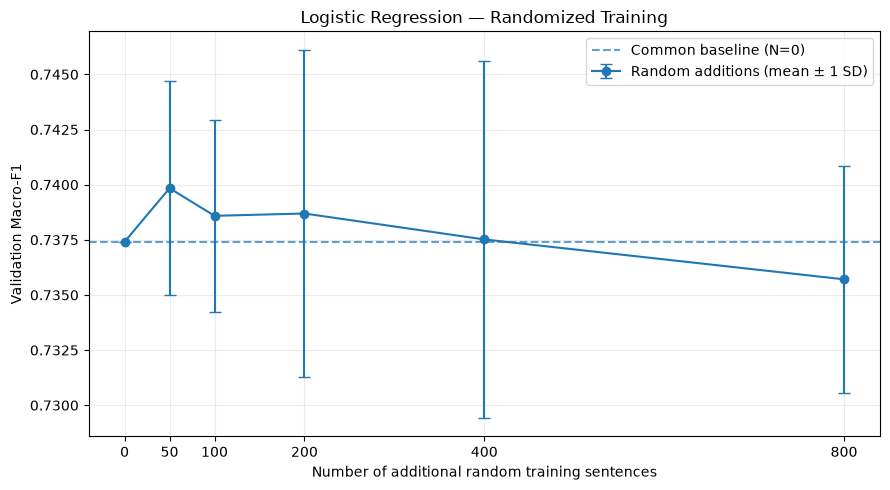

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    summary_df["n_added"],
    summary_df["mean_macro_f1"],
    yerr=summary_df["sd_macro_f1"],
    marker="o", capsize=4,
    label="Random additions (mean ± 1 SD)",
)
ax.axhline(base_f1, linestyle="--", alpha=0.7, label="Common baseline (N=0)")
ax.set_xlabel("Number of additional random training sentences")
ax.set_ylabel("Validation Macro-F1")
ax.set_title("Logistic Regression — Randomized Training")
ax.set_xticks(SAMPLE_SIZES)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "random_learning_curve.png", dpi=160, bbox_inches="tight")
plt.show()